In [15]:
import pandas as pd 
import numpy as np

DATOS

In [16]:
datos= pd.read_excel("datos/datos_limpio_automovil.xlsx")

In [17]:
datos.head()

,Unnamed: 0,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,...,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,0,O77MPJ,26,19153,6973,706,9,1,19.05,36,...,False,True,False,False,False,True,False,False,False,True
1,8,IYOL1S,29,39531,40000,826,0,1,9.74,24,...,False,False,False,False,False,True,False,True,False,False
2,9,FRMZVN,29,40348,16448,740,9,1,14.73,24,...,False,False,True,False,False,True,False,False,False,True
3,26,YKHXVY,38,41732,42040,661,173,2,13.24,48,...,False,True,False,False,False,False,True,True,False,False
4,32,NHDJTK,35,35085,16406,759,181,1,9.74,36,...,True,False,False,False,False,True,False,True,False,False


In [18]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 76924 entries, 0 to 76923
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Unnamed: 0                             76924 non-null  int64  
 1   ID                                     76924 non-null  str    
 2   Edad                                   76924 non-null  int64  
 3   Ingresos                               76924 non-null  int64  
 4   Monto_Inicial                          76924 non-null  int64  
 5   Scoring_Crediticio                     76924 non-null  int64  
 6   Meses_Empleo                           76924 non-null  int64  
 7   Num_Creditos                           76924 non-null  int64  
 8   Ratio_Interes                          76924 non-null  float64
 9   Duracion                               76924 non-null  int64  
 10  Ratio_Deuda_Ingresos                   76924 non-null  float64
 11  Posesion_Hipo

In [19]:
datos = datos.rename(columns={
    "Monto_Inicial": "capital_prestado",
    "Ratio_Interes": "interes_anual",
    "Duracion": "num_meses"
})

COSAS QUE PIDE ESTE OBJETIVO
Calcular el valor presente de las cuotas pendientes a mitad del préstamo con el método seleccionado. 
- Generar el cuadro de amortización (francés o alemán).
- Localizar la mitad del préstamo y ver qué cuotas quedan pendientes.
- Actualizar (descontar) esas cuotas pendientes al momento de la mitad del préstamo para obtener su valor presente

In [20]:
datos.shape

(76924, 27)

In [21]:
datos.columns

Index(['Unnamed: 0', 'ID', 'Edad', 'Ingresos', 'capital_prestado',
       'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'interes_anual',
       'num_meses', 'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado',
       'Estudios_Escolar', 'Estudios_Grado Universitario', 'Estudios_Máster',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero'],
      dtype='str')

SISTEMA FRANCES

In [22]:
lista_guardar_resultado_fr = []

for _, fila in datos.iterrows():
    # 1) Datos del préstamo
    capital = fila["capital_prestado"]
    interes_anual = fila["interes_anual"]
    duracion = int(fila["num_meses"])

    # 2) Interés mensual
    i = interes_anual / 100 / 12

    # 3) Cuota francesa
    cuota = capital * (i * (1 + i) ** duracion) / ((1 + i) ** duracion - 1)

    # 4) Mitad del préstamo
    mitad = duracion // 2

    # 5) Valor presente de las cuotas pendientes
    vp = 0
    for t in range(1, duracion - mitad + 1):
        vp += cuota / (1 + i) ** t

    # 6) Guardar el resultado de este préstamo
    lista_guardar_resultado_fr.append(vp)

print(len(lista_guardar_resultado_fr))    # debe salir 76924

76924


In [23]:
datos["VP_Frances"] = lista_guardar_resultado_fr
print(datos[["ID", "VP_Frances"]].head())

       ID    VP_Frances
0  O77MPJ   3977.437228
1  IYOL1S  20969.308436
2  FRMZVN   8824.937288
3  YKHXVY  23771.920682
4  NHDJTK   8798.759549


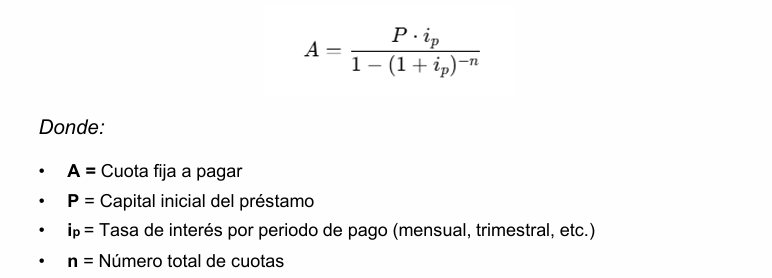

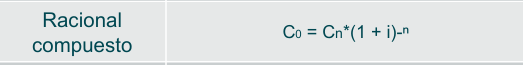

Para calcular el valor presente de las cuotas pendientes se ha utilizado el método de actualización mediante descuento racional compuesto, ya que las cuotas futuras se descuentan empleando el tipo de interés periódico del préstamo y considerando el efecto de la capitalización compuesta a lo largo del tiempo.